# Proyecto 2 - VectorIA
## Módulo 2: Predicción de Casos Semanales de Dengue (RNN / LSTM)

**Objetivo:** Predecir los casos de dengue para las próximas 4 semanas utilizando datos históricos semanales y variables climáticas (temperatura máxima/mínima, lluvia, humedad y componentes estacionales).

**Comparativa obligatoria (Rúbrica):**
1. **Baseline Estacional:** Mismo valor de casos reportado en la misma semana del año anterior.
2. **Modelo Base:** `SimpleRNN` (32 unidades).
3. **Modelo Principal:** `LSTM` multicapa (64 unidades $\rightarrow$ 32 unidades $\rightarrow$ Dropout 0.2 $\rightarrow$ Dense 4).

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from src.train.lstm import LstmModel

### 1. Carga de Datos y Preprocesamiento
Se cargan los registros nacionales oficiales de casos y clima (`data/raw/vectoria_dengue_nacional_real.csv`). Se generan rezagos (lags 1 a 4) y componentes cíclicos senoidales para la estacionalidad.

In [2]:
ruta_csv = '../data/raw/vectoria_dengue_nacional_real.csv'
df_raw = pd.read_csv(ruta_csv)
print(f"✓ Registros cargados: {df_raw.shape[0]} semanas (2014-2024)")
df_raw.head()

✓ Registros cargados: 574 semanas (2014-2024)


,fecha_inicio_semana,anio,semana_epi,provincia,region_climatica,poblacion,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
0,2013-12-29,2014,1,Costa Rica,Nacional,5170000,239,4.62,11.0,27.2,19.9,84.9
1,2014-01-05,2014,2,Costa Rica,Nacional,5170000,257,4.97,8.9,27.0,19.7,83.8
2,2014-01-12,2014,3,Costa Rica,Nacional,5170000,184,3.56,4.5,27.1,19.5,81.7
3,2014-01-19,2014,4,Costa Rica,Nacional,5170000,156,3.02,7.7,27.1,19.5,80.0
4,2014-01-26,2014,5,Costa Rica,Nacional,5170000,189,3.66,4.7,27.2,18.7,78.0


### 2. Inicialización y Preparación de Ventanas Temporales
Se utiliza una ventana histórica de 26 semanas ($t-26 \dots t$) para proyectar el horizonte de 4 semanas a futuro. La partición temporal deja las últimas 52 semanas (1 año epidemiológico completo) para prueba.

In [3]:
modelo_lstm = LstmModel(filepath=ruta_csv, length=26, horizon=4)
scaled_train, scaled_test = modelo_lstm.preparar_datos(df_raw, test_size=52)

print(f"✓ Columnas de entrada ({len(modelo_lstm.feature_cols)}):\n{modelo_lstm.feature_cols}")
print(f"✓ Filas train escaladas: {scaled_train.shape[0]} | Filas test escaladas: {scaled_test.shape[0]}")

✓ Columnas de entrada (24):
['casos_dengue', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct', 'semana_sin', 'semana_cos', 'semana_epi', 'lluvia_mm_lag1', 'lluvia_mm_lag2', 'lluvia_mm_lag3', 'lluvia_mm_lag4', 'temp_max_c_lag1', 'temp_max_c_lag2', 'temp_max_c_lag3', 'temp_max_c_lag4', 'temp_min_c_lag1', 'temp_min_c_lag2', 'temp_min_c_lag3', 'temp_min_c_lag4', 'humedad_rel_pct_lag1', 'humedad_rel_pct_lag2', 'humedad_rel_pct_lag3', 'humedad_rel_pct_lag4']
✓ Filas train escaladas: 518 | Filas test escaladas: 52


### 3. Entrenamiento del Modelo Base (SimpleRNN) y Modelo Principal (LSTM)

In [4]:
historia = modelo_lstm.entrenar(scaled_train, scaled_test, epochs=40, batch_size=16)

Entrenamiento de baseline: SimpleRNN


C:\Users\rober\OneDrive\Desktop\Proyecto_2_VectorIA\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Entrenamiento del modelo LSTM
Entrenamiento finalizado con éxito


### 4. Evaluación Oficial y Comparativa de Métricas (RMSE / MAE)

In [5]:
resultados = modelo_lstm.evaluar_metricas(scaled_test)
metricas = resultados['metrics']

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 141ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step
 Se muestra una comparativa de las métricas
1. Baseline Estacional (Año Anterior) -> RMSE: 686.70 | MAE: 559.83
2. Modelo Base (SimpleRNN)            -> RMSE: 343.76 | MAE: 277.60
3. Modelo Principal (LSTM)            -> RMSE: 184.08 | MAE: 162.19


### 5. Gráfico de Comparación en el Conjunto de Test

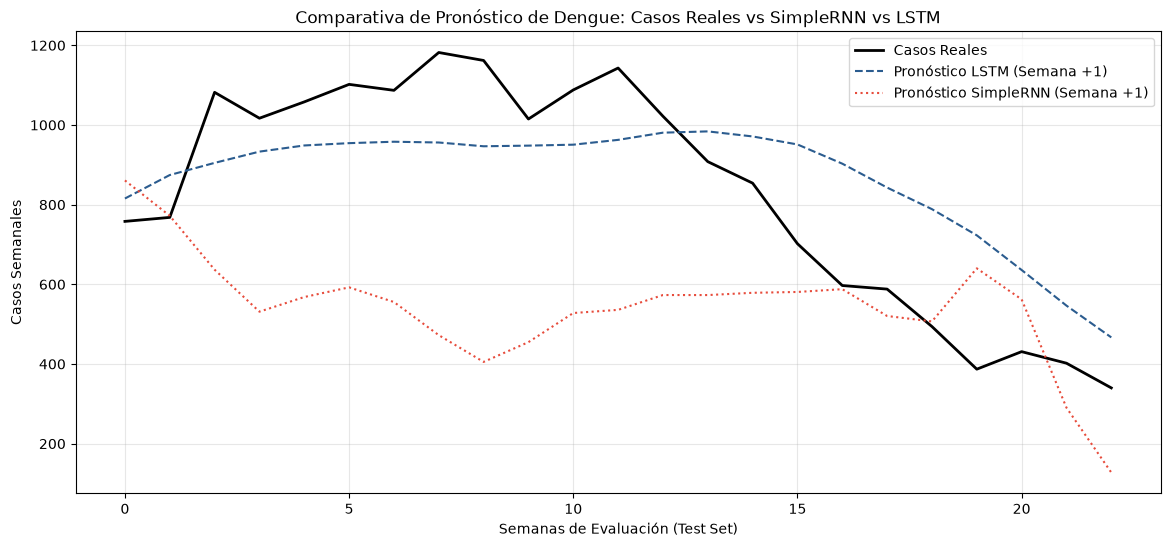

In [6]:
y_true = resultados['y_true']
y_pred_lstm = resultados['y_pred_lstm']
y_pred_rnn = resultados['y_pred_rnn']

# Graficamos la primera semana del horizonte pronosticado a lo largo del periodo de test
plt.figure(figsize=(14, 6))
plt.plot(y_true[:, 0], label='Casos Reales', color='black', linewidth=2)
plt.plot(y_pred_lstm[:, 0], label='Pronóstico LSTM (Semana +1)', color='#2b5c8f', linestyle='--')
plt.plot(y_pred_rnn[:, 0], label='Pronóstico SimpleRNN (Semana +1)', color='#e74c3c', linestyle=':')
plt.title('Comparativa de Pronóstico de Dengue: Casos Reales vs SimpleRNN vs LSTM')
plt.xlabel('Semanas de Evaluación (Test Set)')
plt.ylabel('Casos Semanales')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 6. Guardado de Modelos y Escalador
Se persisten los artefactos para consumo en la API de FastAPI y en la aplicación Streamlit.

In [7]:
Path('../models').mkdir(parents=True, exist_ok=True)
modelo_lstm.model_lstm.save('../models/lstm_casos.keras')
joblib.dump(modelo_lstm.scaler, '../models/scaler_lstm.joblib')
print("✓ Modelo LSTM guardado en: ../models/lstm_casos.keras")
print("✓ Escalador guardado en: ../models/scaler_lstm.joblib")

✓ Modelo LSTM guardado en: ../models/lstm_casos.keras
✓ Escalador guardado en: ../models/scaler_lstm.joblib
